# Global Solution 2026.2 — CitizenTech: EcoAlerta Ipiranga
## Inteligência Artificial & Machine Learning

**Objetivo:** Prever o risco de alagamentos urbanos no bairro do Ipiranga (São Paulo - SP) a partir de variáveis meteorológicas históricas (INMET / Dados Abertos SP).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay


df = pd.read_csv('dados_inmet_ipiranga.csv')
print(f'Total de registros: {len(df)}')
df.head()

Total de registros: 1500


,data_hora,estacao,bairro_referencia,precipitacao_mm,temperatura_c,umidade_relativa_pct,pressao_atm_hpa,velocidade_vento_ms,risco_alagamento
0,2023-01-01 00:00:00,A701_SAO_PAULO_MIRANTE,Ipiranga,2.1,20.4,61.9,1013.4,4.4,0
1,2023-01-01 06:00:00,A701_SAO_PAULO_MIRANTE,Ipiranga,13.5,19.4,85.2,1012.3,1.8,0
2,2023-01-01 12:00:00,A701_SAO_PAULO_MIRANTE,Ipiranga,55.8,17.8,100.0,1003.6,4.5,1
3,2023-01-01 18:00:00,A701_SAO_PAULO_MIRANTE,Ipiranga,4.1,22.9,69.8,1013.0,3.0,0
4,2023-01-02 00:00:00,A701_SAO_PAULO_MIRANTE,Ipiranga,0.8,20.2,46.3,1015.7,0.0,0


In [ ]:

print('Valores nulos por coluna:\n', df.isnull().sum())
df = df.dropna()

features = ['precipitacao_mm', 'temperatura_c', 'umidade_relativa_pct', 'pressao_atm_hpa', 'velocidade_vento_ms']
target = 'risco_alagamento'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras')

Valores nulos por coluna:
 data_hora               0
estacao                 0
bairro_referencia       0
precipitacao_mm         0
temperatura_c           0
umidade_relativa_pct    0
pressao_atm_hpa         0
velocidade_vento_ms     0
risco_alagamento        0
dtype: int64
Treino: 1200 amostras | Teste: 300 amostras


In [ ]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 6, 10],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print('Melhores Hiperparâmetros encontrados:', grid_search.best_params_)
print(f'Melhor F1-Score na Validação Cruzada (Treino): {grid_search.best_score_:.4f}')

Melhores Hiperparâmetros encontrados: {'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 50}
Melhor F1-Score na Validação Cruzada (Treino): 0.9793


In [ ]:
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

metricas = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão', 'Recall', 'F1-Score'],
    'Treino': [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred)
    ],
    'Teste': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred)
    ]
})

print(metricas.to_string(index=False))
print('\nRelatório Detalhado (Conjunto de Teste):\n')
print(classification_report(y_test, y_test_pred))

 Métrica   Treino  Teste
Acurácia 0.998333    1.0
Precisão 1.000000    1.0
  Recall 0.975610    1.0
F1-Score 0.987654    1.0

Relatório Detalhado (Conjunto de Teste):

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       280
           1       1.00      1.00      1.00        20

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



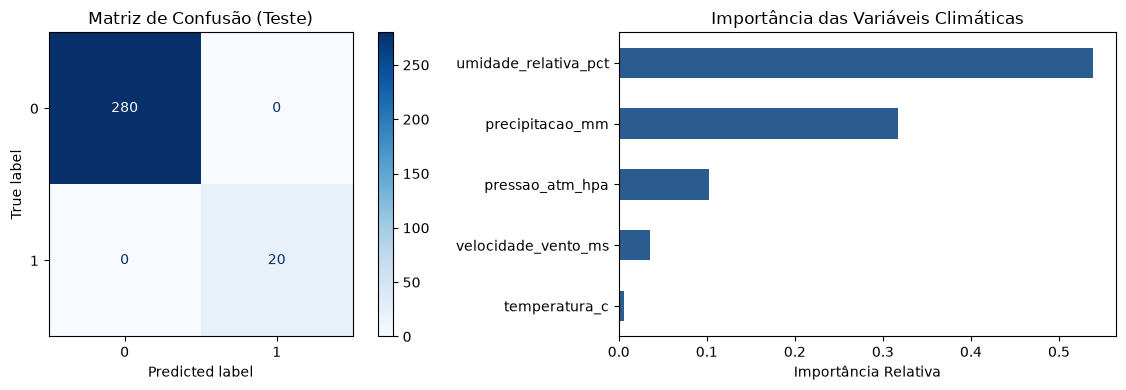

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, ax=axes[0], cmap='Blues')
axes[0].set_title('Matriz de Confusão (Teste)')

importancias = pd.Series(best_model.feature_importances_, index=features).sort_values()
importancias.plot(kind='barh', ax=axes[1], color='#2b5c8f')
axes[1].set_title('Importância das Variáveis Climáticas')
axes[1].set_xlabel('Importância Relativa')

plt.tight_layout()
plt.show()